# Training and Test Errors, Cross-Validation, Pipelines

In [1]:
import pandas as pd
import numpy as np

from plotnine import *

**Use scikit-learn, including pipelines, whenever possible.**

## Ames Housing Data


We have fit different regression models to predict house prices (SalePrice, not log). Now we will evaluate models by estimating their prediction error.

In [2]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


Since all of the houses in the data set have a SalePrice, we'll include all the observations in the training data. We'll start with a basic linear regression model with a few features.

In [3]:
X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]

y_train = df_ames["SalePrice"]

In [4]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(
    X=X_train,
    y=y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 118.1 ,-29994.96, 26728.53, 1271.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.694e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


1. Explain conceptually what the "fit" step does. What is the output?

In [5]:
round(model1.intercept_)
pd.Series(model1.coef_, index = X_train.columns)

Gr Liv Area        118.099868
Bedroom AbvGr   -29994.956760
Full Bath        26728.533428
Half Bath         1271.138477
dtype: float64

The fit step estimates the intercept and coefficients that minimize the squared differences between the observed and predicted sale prices. Its output is a fitted linear regression model containing those estimated coefficients, which define the prediction equation.

\[
\begin{aligned}
\hat{y}_i
&= 46942 + 118.09x_{1i} - 29994.96x_{2i} \\
&\quad + 26728x_{3i} + 1271x_{4i}
\end{aligned}
\]

2. Explain conceptually how you would compute the *training* RMSE (root mean square error) of this model.

How far the predicted values are from the observed values in the same units as the observed values

In [6]:
import numpy as np
from sklearn.metrics import root_mean_squared_error

predicted = model1.predict(X_train)

residual_squared = (y_train - predicted) ** 2
by_hand_rmse = np.sqrt(residual_squared.mean())

cpu_rmse = root_mean_squared_error(y_train, predicted)

print("By-hand RMSE:", by_hand_rmse)
print("Scikit-learn RMSE:", cpu_rmse)

By-hand RMSE: 51350.41833606974
Scikit-learn RMSE: 51350.41833606974


In [7]:
y_train.std()

79886.69235666493

3. Interpret the *training RMSE*. Is it big or small? What could you use as a rough benchmark for comparison?

In [8]:
y_train.std()

79886.69235666493

RMSE is how far each observed value deviate from the predicted value on average and the mechanism to determine whether that value is big or small is to compare the RMSE to the standard deviation of the response variable. So if the RMSE is smaller than the standrard deviation of the response variable than the model has explained variability in the response variable. 

4. Suppose we add more features like "TotRms AbvGrd" and fit a new model. Would the *training* RMSE increase or decrease? Why is comparing the *training* RMSE of these two models not useful?

When we add more features into the model, the RMSE will either stay the same or decrease, it can't increase. When comparing these two models, just using RMSE is not useful because by statistical modeling the RMSE for the more complicated model will either be the same or smaller than the less complicated model.

5. If we fit a 1-nearest neighbor model, what should the *training* RMSE be?

It should be 0 in that when we choose the nearest neighbor from the training dataset we should essentially pick the same value as the predicted value. However, there are times when there are ties that would cause the RMSE not to be exactly 0. 

6. What happens to the *training* RMSE of a $k$-nearest neighbors model as $k$ increases?

In [9]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor

rows = []

for k in [1, 200, 500, 1000, len(X_train)]:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)

    predicted = knn.predict(X_train)
    residual_squared = (y_train - predicted) ** 2
    rmse = np.sqrt(residual_squared.mean())

    rows.append([k, rmse])

pd.DataFrame(rows, columns=["k", "training RMSE"])

,k,training RMSE
0,1,21659.074722
1,200,56254.845932
2,500,58070.950046
3,1000,61023.643560
4,2930,79873.058652


As k increases, the training RMSE generally increases because each prediction averages over more neighboring houses and fits each individual training observation less closely.

7. We are really interested in the *test* RMSE, not the *training* RMSE. Explain why in practice you can not compute the *test* RMSE.

We are going to use the RMSE of the test data to compare mdoels rathers than compare the RMSE of the training data. In practice we may not have access to target variable of the test data. So we have to use the training informatio to determine which model to use

8. Explain conceptually how cross-validations *estimates* the *test* RMSE.

State that K-fold Cross Validation, break up the data into K folds and run a model and calculate the rmse for each fold. K=10. 

1. Cut the data set into 10 folds
2. Drop 1 of the 10 folds, use the other 9 folds to create a model and test it on the dropped fold
3. Repeat this process for each one of the folds
4. Average of the RMSE to determine the RMSE fro the test dataset.

9. We'll use cross-validation to estimate the *test* RMSE for the model from part 1. Will the *test* RMSE be greater than, less than, or equal to the *training* RMSE for this model?

The test RMSE should generally be greater than the training RMSE. The model was fitted to minimize errors on the training data, so its performance on those observations is optimistically low. Cross-validation evaluates the model on observations that were not used to fit it.

For this model, the training RMSE is approximately $51,350, while the estimated test RMSE is approximately $52,093.

10. Suppose we add features like we did in part 4. Will the *test* RMSE necessarily decrease? Fit the test RMSE and compare the two models - which is better based on this criteria?

Adding features does not necessarily decrease the test RMSE. Although additional predictors cannot increase the training RMSE, they may add noise or cause overfitting, resulting in a higher test RMSE.

In [12]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
import numpy as np

# Original model
X_model1 = df_ames[
    ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
]

scores1 = cross_val_score(
    LinearRegression(),
    X_model1,
    y_train,
    scoring="neg_mean_squared_error",
    cv=10
)

test_rmse1 = np.sqrt(-scores1.mean())


# Model with the additional feature
X_model2 = df_ames[
    [
        "Gr Liv Area",
        "Bedroom AbvGr",
        "Full Bath",
        "Half Bath",
        "TotRms AbvGrd"
    ]
]

scores2 = cross_val_score(
    LinearRegression(),
    X_model2,
    y_train,
    scoring="neg_mean_squared_error",
    cv=10
)

test_rmse2 = np.sqrt(-scores2.mean())

print("Original model test RMSE:", test_rmse1)
print("Expanded model test RMSE:", test_rmse2)



Original model test RMSE: 52093.44327663409
Expanded model test RMSE: 52214.16057287575


Based on test RMSE, the original model is slightly better because it has the lower estimated test RMSE. Adding TotRms AbvGrd did not improve out-of-sample predictive performance.

11. Now suppose we add a categorical predictor like Neighborhood. The crossval code below will (probably) error. Explain why. Hint: think about how the cross-validation process works and how categorical variables are treated.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],),
     ("dummify", OneHotEncoder(handle_unknown="ignore"), ["Neighborhood"]),
    ],
    remainder="drop",
)

neighborhood_model = Pipeline(
    [("preprocessing", ct),
     ("lm", LinearRegression())]
)

X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]]
y_train = df_ames["SalePrice"]

neighborhood_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath','Neighborhood']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [26]:
scores = cross_val_score(neighborhood_model,
                         X = X_train,
                         y = y_train,
                         scoring="neg_mean_squared_error",
                         cv=10)
scores

array([-1.44545960e+09, -2.17595046e+09, -1.03959067e+09, -1.75337711e+09,
       -1.09461091e+09, -2.46145139e+09, -1.41979799e+09, -2.32075542e+09,
       -1.21633488e+09, -1.03469980e+09])

The code may error because a neighborhood could appear in a validation fold without appearing in the training folds. Since OneHotEncoder only learns the categories in the training folds, it will not recognize that neighborhood when making predictions.

Adding `handle_unknown="ignore"` prevents the error by setting all neighborhood indicator columns to zero for an unfamiliar neighborhood.

11. Going back to part 1, suppose we had standardized the features first. Would the coeffiecients of the fitted model change? Would the *training* RMSE change?

The coefficients would change because standardization changes the scale of the predictors. Each coefficient would represent the predicted change in SalePrice for a one-standard-deviation increase in that predictor instead of a one-unit increase. However, the predicted prices would remain the same, so the training RMSE would not change.

12. Suppose we want to standardize predictors like in the previous part and estimate test RMSE using cross-validation. Explain how standardization fits in in the CV process. Also explain why it is important to put standardization as part of the model pipeline.

During cross-validation, each fold is treated as a separate train/test split. For each fold, the standardizer should be fitted only on that fold’s training observations. The mean and standard deviation learned from the training fold are then used to standardize both the training fold and the validation fold. The regression model is fitted on the standardized training fold and evaluated on the standardized validation fold.

It is important to include standardization in the pipeline because the pipeline repeats this process correctly for every fold. If we standardized the entire dataset before cross-validation, information from the validation observations would influence the means and standard deviations used for training. This would cause data leakage and could make the estimated test RMSE too optimistic.

## Practice Activity

We'll continue with the housing data and our goal of predicting Sale Price.

We will have a competition to see who can come up with the model with the smallest *test* RMSE. Fit several models and try to find the smallest *test* RMSE. Use cross-validation to estimate the *test* RMSE. When you think you have a good model, share your it and its test RMSE with a partner. Then see what other people have done; can you do even better?

Note: next week we will see how to make some of these choices in a more automated way. For now just work by trial and error. You should try:

- Exploring the data first! Make some plots and summaries to get an idea of what might be good predictors to try
- Several different sets of predictors, including both categorical and numerical predictors
- Linear regression models, including models with polynomial features and interactions
- K-nearest neighbors models, inclduing different values of k
- Decision trees, including different sizes of trees

Use pipelines as much as possible, and don't forget to transform variables as needed.

In [30]:
from plotnine import ggplot, aes, geom_point, geom_smooth, labs

from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold

In [32]:
df_ames.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


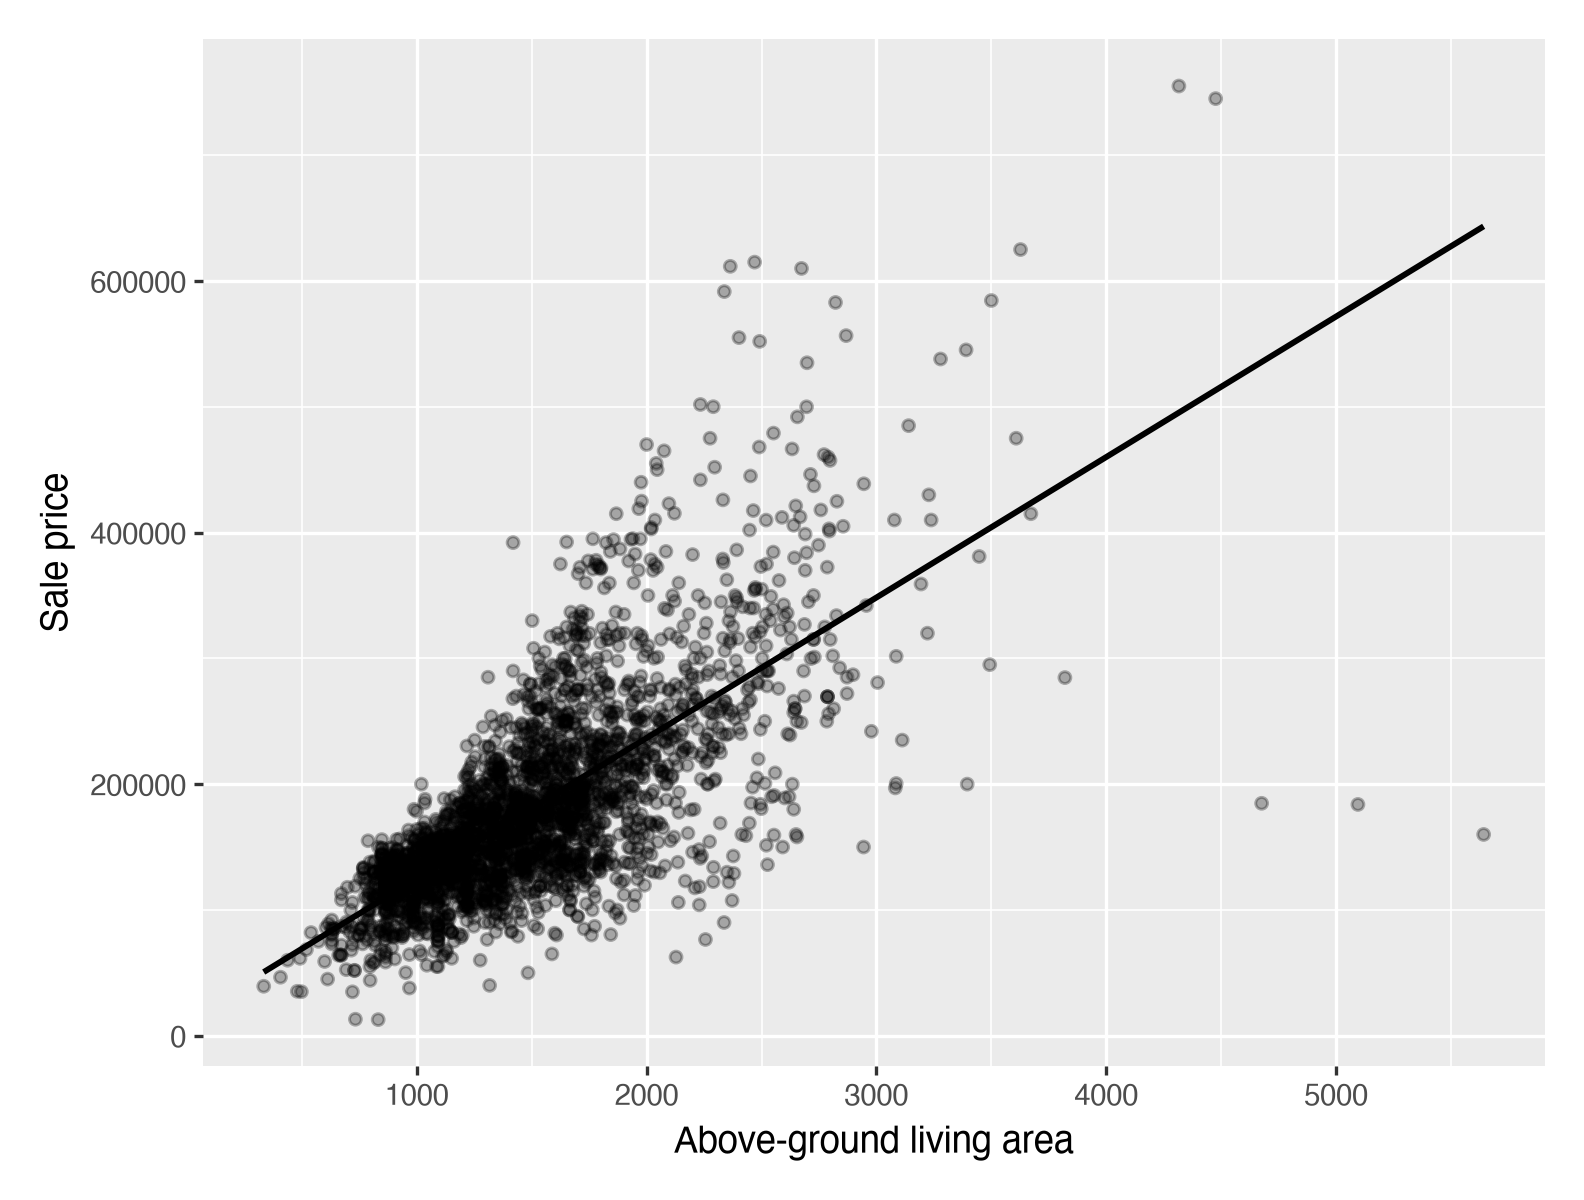

In [33]:
(
    ggplot(df_ames, aes(x="Gr Liv Area", y="SalePrice"))
    + geom_point(alpha=0.3)
    + geom_smooth(method="lm", se=False)
    + labs(
        x="Above-ground living area",
        y="Sale price"
    )
)

In [34]:
(
    df_ames
    .groupby("Neighborhood")["SalePrice"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

,count,mean,median
Neighborhood,,,
NoRidge,71,330319.126761,302000.0
StoneBr,51,324229.196078,319000.0
NridgHt,166,322018.265060,317750.0
GrnHill,2,280000.000000,280000.0
Veenker,24,248314.583333,250250.0
Timber,72,246599.541667,232106.5
Somerst,182,229707.324176,225500.0
ClearCr,44,208662.090909,197500.0
Crawfor,103,207550.834951,200624.0


In [35]:
basic_numeric_features = [
    "Gr Liv Area",
    "Bedroom AbvGr",
    "Full Bath",
    "Half Bath"
]

expanded_numeric_features = [
    "Gr Liv Area",
    "Bedroom AbvGr",
    "Full Bath",
    "Half Bath",
    "Overall Qual",
    "Year Built"
]

categorical_features = [
    "Neighborhood"
]

all_features = expanded_numeric_features + categorical_features

X = df_ames[all_features]
y = df_ames["SalePrice"]

In [36]:
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

results = []

In [37]:
def evaluate_model(name, model):
    fold_rmse = -cross_val_score(
        model,
        X,
        y,
        scoring="neg_root_mean_squared_error",
        cv=cv
    )

    results.append({
        "Model": name,
        "CV RMSE": fold_rmse.mean(),
        "RMSE SD": fold_rmse.std()
    })

    print("Model:", name)
    print("Average CV RMSE:", round(fold_rmse.mean()))
    print("RMSE SD:", round(fold_rmse.std()))

In [38]:
basic_preprocessing = ColumnTransformer(
    [
        (
            "standardize",
            StandardScaler(),
            basic_numeric_features
        )
    ],
    remainder="drop"
)

basic_linear_model = Pipeline(
    [
        ("preprocessing", basic_preprocessing),
        ("model", LinearRegression())
    ]
)

evaluate_model(
    "Basic linear regression",
    basic_linear_model
)

Model: Basic linear regression
Average CV RMSE: 51425
RMSE SD: 4235


In [39]:
expanded_preprocessing = ColumnTransformer(
    [
        (
            "standardize",
            StandardScaler(),
            expanded_numeric_features
        )
    ],
    remainder="drop"
)

expanded_linear_model = Pipeline(
    [
        ("preprocessing", expanded_preprocessing),
        ("model", LinearRegression())
    ]
)

evaluate_model(
    "Expanded numerical linear regression",
    expanded_linear_model
)

Model: Expanded numerical linear regression
Average CV RMSE: 38183
RMSE SD: 4551


In [40]:
mixed_preprocessing = ColumnTransformer(
    [
        (
            "standardize",
            StandardScaler(),
            expanded_numeric_features
        ),
        (
            "dummify",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

neighborhood_linear_model = Pipeline(
    [
        ("preprocessing", mixed_preprocessing),
        ("model", LinearRegression())
    ]
)

evaluate_model(
    "Linear regression with neighborhood",
    neighborhood_linear_model
)

Model: Linear regression with neighborhood
Average CV RMSE: 35035
RMSE SD: 3286


In [41]:
numeric_polynomial_preprocessing = Pipeline(
    [
        ("standardize", StandardScaler()),
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        )
    ]
)

polynomial_preprocessing = ColumnTransformer(
    [
        (
            "numeric",
            numeric_polynomial_preprocessing,
            expanded_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

polynomial_linear_model = Pipeline(
    [
        ("preprocessing", polynomial_preprocessing),
        ("model", LinearRegression())
    ]
)

evaluate_model(
    "Polynomial linear regression",
    polynomial_linear_model
)

Model: Polynomial linear regression
Average CV RMSE: 30762
RMSE SD: 2667


In [42]:
knn_10_model = Pipeline(
    [
        ("preprocessing", mixed_preprocessing),
        (
            "model",
            KNeighborsRegressor(n_neighbors=10)
        )
    ]
)

evaluate_model(
    "KNN with k=10",
    knn_10_model
)

Model: KNN with k=10
Average CV RMSE: 33555
RMSE SD: 2871


In [43]:
knn_30_model = Pipeline(
    [
        ("preprocessing", mixed_preprocessing),
        (
            "model",
            KNeighborsRegressor(n_neighbors=30)
        )
    ]
)

evaluate_model(
    "KNN with k=30",
    knn_30_model
)

Model: KNN with k=30
Average CV RMSE: 35188
RMSE SD: 2900


In [44]:
tree_depth_4_model = Pipeline(
    [
        ("preprocessing", mixed_preprocessing),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=4,
                random_state=42
            )
        )
    ]
)

evaluate_model(
    "Decision tree with depth=4",
    tree_depth_4_model
)

Model: Decision tree with depth=4
Average CV RMSE: 38049
RMSE SD: 1822


In [45]:
tree_depth_8_model = Pipeline(
    [
        ("preprocessing", mixed_preprocessing),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

evaluate_model(
    "Decision tree with depth=8",
    tree_depth_8_model
)

Model: Decision tree with depth=8
Average CV RMSE: 33224
RMSE SD: 2244


In [46]:
results_df = (
    pd.DataFrame(results)
    .sort_values("CV RMSE")
    .reset_index(drop=True)
)

results_df

,Model,CV RMSE,RMSE SD
0,Polynomial linear regression,30761.793292,2667.033809
1,Decision tree with depth=8,33224.254156,2244.341898
2,KNN with k=10,33555.477492,2871.366444
3,Linear regression with neighborhood,35035.054350,3285.906567
4,KNN with k=30,35188.463640,2900.248383
5,Decision tree with depth=4,38048.534852,1821.717462
6,Expanded numerical linear regression,38183.454588,4551.335972
7,Basic linear regression,51424.981400,4234.618663


In [47]:
results_df.iloc[0]

Model      Polynomial linear regression
CV RMSE                    30761.793292
RMSE SD                     2667.033809
Name: 0, dtype: object

I compared several linear regression, K-nearest neighbors, and decision-tree models using 10-fold cross-validation. The best-performing model was polynomial linear regression, with an estimated test RMSE of approximately $30,762. This means its predictions for unseen houses are typically about $30,762 away from the actual sale prices.